In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
import random
from tqdm.notebook import tqdm
import seaborn as sns
from qpsolvers import solve_qp
from itertools import product
from skophys.preprocessing import Vectorizer, UnVectorizer
import tifffile
import scipy

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.
/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

# Top left corner of movie

In [3]:
movie = tifffile.imread("/home/kushal/caiman_data/example_movies/demoMovie.tif")[:, :40, :50]
movie.shape

(2000, 40, 50)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
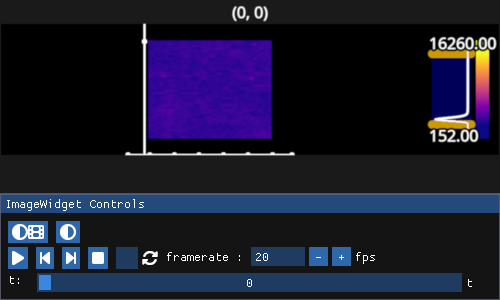

In [4]:
iw_movie = fpl.ImageWidget(movie)
iw_movie.show()

In [5]:
from skimage.transform import downscale_local_mean

# Subsample movie

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
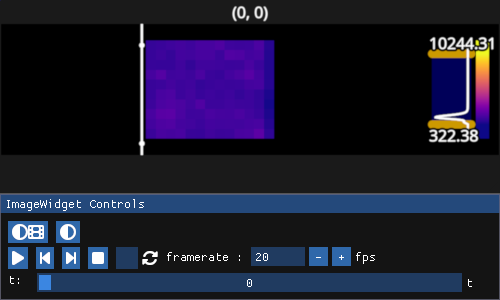

In [6]:
movie_sub = downscale_local_mean(movie, factors=(1, 4, 4))
fpl.ImageWidget(movie_sub).show()

# Vectorize

In [7]:
unvec = UnVectorizer(movie_sub.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie_sub)

In [8]:
X.shape

(130, 2000)

In [9]:
n_pixels = X.shape[0]

In [10]:
lag = 4
lag_step = 1

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

In [11]:
H.shape

(1040, 1993)

In [12]:
mu0 = H[:lag * n_pixels].mean(axis=1)
mu1 = H[lag * n_pixels:].mean(axis=1)

In [13]:
H[:lag * n_pixels] -= mu0[:, None]
H[lag * n_pixels:] -= mu1[:, None]

In [14]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

# k: number of components

In [15]:
k = 5

# list of slices of lags, each slice is the indices in `W` that represent pixels for one lag time

In [16]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag * 2)]
lag_slices

[slice(0, 130, None),
 slice(130, 260, None),
 slice(260, 390, None),
 slice(390, 520, None),
 slice(520, 650, None),
 slice(650, 780, None),
 slice(780, 910, None),
 slice(910, 1040, None)]

In [24]:
PP = past @ past.T / past.shape[1]
FF = future @ future.T / future.shape[1]
PF = past @ future.T / past.shape[1]

PP_inv_sqrt = np.linalg.pinv(scipy.linalg.sqrtm(PP))
FF_inv_sqrt = np.linalg.pinv(scipy.linalg.sqrtm(FF))

K_bar = PP_inv_sqrt @ PF @ FF_inv_sqrt

U, S, Vh = np.linalg.svd(K_bar, full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = PP_inv_sqrt @ U
right_vec = FF_inv_sqrt @ Vh.T

# projection of data onto left and right singular vectors
# proj_left = past.T @ left_vec
# proj_right = future.T @ right_vec

proj_left = left_vec.T @ past
proj_right = right_vec.T @ future

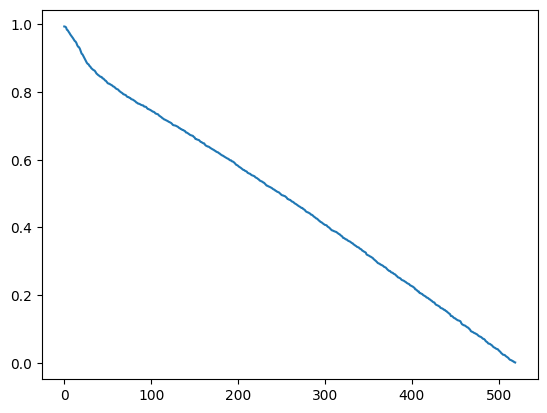

In [28]:
plt.plot(S)

In [34]:
Y = proj_left + proj_right

In [36]:
Y.min()

np.float64(-15.060595077284539)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
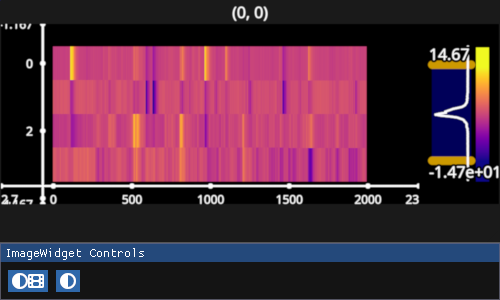

In [38]:
fpl.ImageWidget(Y[:4]).show(maintain_aspect=False)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
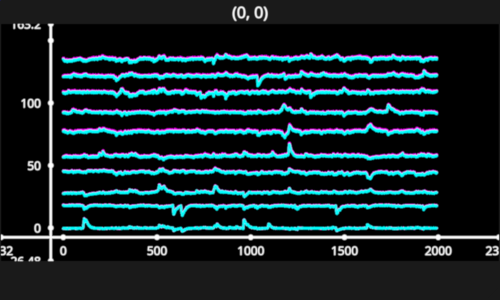

In [45]:
fig = fpl.Figure()

# fig[0, 0].add_line_stack(Y[:10])
fig[0, 0].add_line_stack(proj_left[:10], colors="magenta", alpha=0.4)
fig[0, 0].add_line_stack(proj_right[:10], colors="cyan", alpha=0.4)

fig.show(maintain_aspect=False)